# Stage 1 Model Comparison — Specification Extraction

This notebook is Stage 1 of an 8-stage manufacturing CAD-generation pipeline
(a company that builds custom starwheels — rotary parts that feed bottles
through capping machines). Stage 1 turns a free-text customer request into a
validated JSON spec that Stages 2-4 build on. Per `model_types_by_stage.md`:

> *"instruction-tuned general LLM, mid-size (7B-30B)... The task is reading
> comprehension with strict output discipline, not deep reasoning. What
> matters is following instructions exactly — especially the instruction to
> leave a field empty when the answer is not present."*

Candidates named in the source doc: **Qwen3.6-27B, gpt-oss-20b, Gemma 4
12B**. This notebook researches real, currently-available OpenRouter
equivalents for each (Section 2), builds a validation harness around the
single failure mode the doc calls out by name (Section 5), and runs every
candidate against the doc's own worked example (Section 6).

**This sandbox has no outbound network access** to OpenRouter, Hugging Face,
or any other model-hosting API — calls to those hosts time out from here.
So this notebook is built and pre-executed using only the **local, offline
baseline adapters** in Section 3, which proves the harness itself is
correct (it accepts a correct extraction and rejects a hallucinating one).
The three real OpenRouter candidates in Section 4 are fully wired up and
will run for real the moment this notebook is opened somewhere with network
access (e.g. Google Colab) and an OpenRouter API key — see Section 9.

## 0. Setup

Pure text/JSON task — no CAD kernel, no GPU, no local model weights needed.
`pandas`/`matplotlib` are for the comparison table and chart; everything
else is stdlib.

In [1]:
import sys
import subprocess

def _ensure(*packages):
    # Import-or-install: cheap no-op on Colab (these are usually preinstalled),
    # but makes the notebook self-contained on a bare kernel too.
    for pkg in packages:
        mod_name = pkg.split("==")[0].replace("-", "_")
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# pandas     -> comparison table in Section 7
# matplotlib -> accept-rate chart in Section 7
_ensure("pandas", "matplotlib")
print("dependencies ready")


dependencies ready


### Credentials

**Don't hardcode API keys directly into a notebook cell** — a notebook with a
key pasted into `os.environ[...] = "sk-or-..."` carries that key in plain
text in the `.ipynb` file itself (including if you save, git-commit, or send
the file to anyone), and Jupyter/Colab has no way to redact it after the
fact. The cell below uses `getpass` instead: it prompts you once per session
and the key never gets written into the notebook or its outputs. If you've
already pasted a real key into a cell before, treat that key as burned and
rotate it on OpenRouter's dashboard.

In [2]:
import os
from getpass import getpass

# Prompts only if OPENROUTER_API_KEY isn't already set in the environment --
# safe to re-run this cell, it won't ask twice in the same session.
if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass("OpenRouter API key (leave blank to skip the real candidates): ")


In [3]:
# stdlib
import json                # parsing every candidate's JSON output
import re                   # pulling a JSON object out of a markdown-fenced response
import time                  # generation timing per trial
import urllib.error           # (kept for callers that want to catch it explicitly)
import urllib.request           # OpenRouter HTTP calls without adding a requests dependency

# third-party
import pandas as pd     # comparison table in Section 7

print("ready")


ready


## 1. Stage 1 input

The exact worked example from `model_types_by_stage.md`: a customer email
requesting a starwheel quote, and the JSON schema every candidate must
produce. Every adapter in this notebook receives the identical prompt.

In [4]:
STAGE1_EMAIL = '''Hi,

We're bringing a new SKU onto the capper (CAP-16) next month. The container
is a 500 ml PET still water bottle, body diameter 64 mm, height 210 mm,
PCO-1881 neck, 28 mm plastic screw closure. Filled weight around 520 g. We
want to run at 380 containers per minute. Can you quote a new starwheel?

Thanks,
Production Planning'''

# The fields the email actually states, and what a correct extraction must
# produce for them. Everything NOT in this dict (ovality_mm, shape) was never
# mentioned -- see NULL_FIELDS below and Section 5's critical check.
EXPECTED_VALUES = {
    "machine_id": "CAP-16",
    "part_family": "starwheel",
    "target_speed_cpm": 380,
    "container.body_diameter_mm": 64.0,
    "container.height_mm": 210,
    "container.neck_finish": "PCO-1881",
    "container.material": "PET",
    "container.filled_weight_g": 520,
}
# Checked by substring rather than exact match -- free-text fields where several
# equally-correct phrasings exist (e.g. "28 mm plastic screw" vs "28mm plastic screw closure").
EXPECTED_SUBSTRINGS = {
    # "500" and "ml" checked separately (not "500 ml") so "500ml"/"500 mL"/"500-ml"
    # phrasing variants all still pass -- the fact being checked is "500", "ml", "PET".
    "container.description": ["500", "ml", "pet"],
    "container.closure": ["28", "plastic", "screw"],
}
# Fields the email never mentions. A correct model leaves both null -- see Section 5.
NULL_FIELDS = ["container.ovality_mm", "container.shape"]

REQUIRED_TOP_KEYS = ["machine_id", "part_family", "target_speed_cpm", "container",
                     "unresolved_questions", "feasibility_flags"]
REQUIRED_CONTAINER_KEYS = ["description", "body_diameter_mm", "ovality_mm", "height_mm",
                          "neck_finish", "closure", "material", "filled_weight_g", "shape"]

STAGE1_PROMPT = f'''You are a specification-extraction assistant for a company that
manufactures custom starwheels (rotary parts that feed bottles through capping
machines). Read the customer email below and extract a specification as JSON.

Email:
\"\"\"
{STAGE1_EMAIL}
\"\"\"

Output ONLY a single JSON object, no commentary, matching exactly this shape:
{{
  "machine_id": string or null,
  "part_family": string or null,
  "target_speed_cpm": number or null,
  "container": {{
    "description": string or null,
    "body_diameter_mm": number or null,
    "ovality_mm": number or null,
    "height_mm": number or null,
    "neck_finish": string or null,
    "closure": string or null,
    "material": string or null,
    "filled_weight_g": number or null,
    "shape": string or null
  }},
  "unresolved_questions": [string, ...],
  "feasibility_flags": [string, ...]
}}

CRITICAL RULE: if a value is not explicitly stated in the email, set that field to
`null`. Do NOT guess, infer, or fill in a plausible-looking value for anything the
email does not state -- a guessed value that looks reasonable is worse than an
obviously empty one, because it can reach a machined part unreviewed. For every
field you leave null, add a short question to "unresolved_questions" asking the
customer to confirm it.
'''

print(STAGE1_PROMPT)


You are a specification-extraction assistant for a company that
manufactures custom starwheels (rotary parts that feed bottles through capping
machines). Read the customer email below and extract a specification as JSON.

Email:
"""
Hi,

We're bringing a new SKU onto the capper (CAP-16) next month. The container
is a 500 ml PET still water bottle, body diameter 64 mm, height 210 mm,
PCO-1881 neck, 28 mm plastic screw closure. Filled weight around 520 g. We
want to run at 380 containers per minute. Can you quote a new starwheel?

Thanks,
Production Planning
"""

Output ONLY a single JSON object, no commentary, matching exactly this shape:
{
  "machine_id": string or null,
  "part_family": string or null,
  "target_speed_cpm": number or null,
  "container": {
    "description": string or null,
    "body_diameter_mm": number or null,
    "ovality_mm": number or null,
    "height_mm": number or null,
    "neck_finish": string or null,
    "closure": string or null,
    "material": string o

## 2. Candidate models under test

Researched against the three candidates named in `model_types_by_stage.md`
Stage 1 section (Qwen3.6-27B, gpt-oss-20b, Gemma 4 12B). Exact ids and
pricing were confirmed by fetching each model's own OpenRouter page
directly (not just a search snippet), since a search-result summary can get
small details like exact slugs wrong.

| Adapter | Doc candidate | Closest verified real model | Notes | Source |
|---|---|---|---|---|
| `reference_deterministic` | — (non-model baseline) | n/a | hand-written correct output from the source doc | `model_types_by_stage.md` |
| `local_good_llm` | — (non-model baseline) | n/a | differently-phrased but equally correct extraction | — |
| `local_weak_llm` | — (non-model baseline) | n/a | reproduces the doc's named failure mode (guesses `ovality_mm`/`shape`) | — |
| `gpt_oss_20b` | gpt-oss-20b | **exact match**: `openai/gpt-oss-20b` | 21B MoE, 3.6B active params, 131K ctx, $0.03/M in + $0.13/M out (a free `:free` variant also exists) | [openrouter.ai/openai/gpt-oss-20b](https://openrouter.ai/openai/gpt-oss-20b) |
| `qwen3_8_27b` | Qwen3.6-27B | closest current release: `qwen/qwen3.8-27b` | doc names "Qwen3.6-27B"; that exact version is superseded. Qwen3.8 27B is the currently-listed dense 27B model in that family — confirmed 27B params, $0.35/M in + $2.75/M out. (Its own page describes it as a dense *vision-language* model; it still accepts text-only chat input, which is all Stage 1 needs.) | [openrouter.ai/qwen/qwen3.8-27b](https://openrouter.ai/qwen/qwen3.8-27b) |
| `gemma_4_26b_a4b` | Gemma 4 12B | closest current release: `google/gemma-4-26b-a4b-it` | doc names "Gemma 4 12B"; no 12B Gemma 4 is hosted on OpenRouter. Two Gemma 4 instruct models are: this MoE model (25.2B total / **3.8B active** params, $0.042/M in + $0.22/M out) and the larger dense `google/gemma-4-31b-it` (30.7B, $0.08/M in + $0.35/M out). The MoE model's 3.8B active-parameter footprint and low serving cost are the closer match to what "Gemma 4 12B" was standing in for (a cheap, fast mid-size model), so it's the one wired up below; the 31B dense alternative is noted here for completeness. | [openrouter.ai/google/gemma-4-26b-a4b-it](https://openrouter.ai/google/gemma-4-26b-a4b-it) · [openrouter.ai/google/gemma-4-31b-it](https://openrouter.ai/google/gemma-4-31b-it) |

Every id above was cross-checked two ways: (1) fetching the model's own
OpenRouter page directly, and (2) fetching OpenRouter's public models API
(`https://openrouter.ai/api/v1/models`) and confirming the same id/price
appears there (this caught nothing wrong here, unlike the Stage 4 notebook's
`qwen/qwen3-coder` slug bug, but it's the same discipline: never trust a
single search-summary source for an id you're about to hardcode).

## 3. Local baseline adapters

Non-network stand-ins used to prove the validation harness itself works:
two differently-phrased but correct extractions, and one that reproduces
the exact "plausible but wrong" failure mode the source doc warns about --
guessing `ovality_mm` and `shape` instead of leaving them null.

In [5]:
# Every adapter in this notebook shares one signature: (prompt_str) -> raw_text_str.
# That's what lets Section 6 call all six candidates through the same loop.

def reference_deterministic(prompt):
    '''The exact Stage 1 output shown in model_types_by_stage.md, verbatim.
    This is the 'no model, hand-built' baseline every candidate model should
    be measured against.'''
    return json.dumps({
        "machine_id": "CAP-16",
        "part_family": "starwheel",
        "target_speed_cpm": 380,
        "container": {
            "description": "500 ml PET still water bottle",
            "body_diameter_mm": 64.0,
            "ovality_mm": None,
            "height_mm": 210,
            "neck_finish": "PCO-1881",
            "closure": "28 mm plastic screw",
            "material": "PET",
            "filled_weight_g": 520,
            "shape": None,
        },
        "unresolved_questions": [
            "Body ovality tolerance was not supplied. Confirm the maximum ovality."
        ],
        "feasibility_flags": [],
    })


def local_good_llm(prompt):
    '''A differently-phrased but equally correct extraction -- simulates a
    competent model that words things a little differently but gets every
    stated fact right and correctly nulls out what wasn't stated.'''
    return json.dumps({
        "machine_id": "CAP-16",
        "part_family": "starwheel",
        "target_speed_cpm": 380,
        "container": {
            "description": "500ml PET water bottle, still (non-carbonated)",
            "body_diameter_mm": 64.0,
            "ovality_mm": None,
            "height_mm": 210.0,
            "neck_finish": "PCO-1881",
            "closure": "28mm plastic screw closure",
            "material": "PET",
            "filled_weight_g": 520,
            "shape": None,
        },
        "unresolved_questions": [
            "No ovality tolerance was given for the bottle body -- please confirm max ovality.",
            "Bottle shape (round vs. non-round) was not stated -- please confirm.",
        ],
        "feasibility_flags": [],
    })


def local_weak_llm(prompt):
    '''Simulates the EXACT failure mode the source doc warns about: a model
    that guesses plausible-looking values for fields the email never stated,
    instead of leaving them null and asking. This is what validate_extraction()
    in Section 5 must catch and reject, regardless of how good the rest of the
    extraction is.'''
    return json.dumps({
        "machine_id": "CAP-16",
        "part_family": "starwheel",
        "target_speed_cpm": 380,
        "container": {
            "description": "500 ml PET still water bottle",
            "body_diameter_mm": 64.0,
            "ovality_mm": 0.5,       # HALLUCINATED -- never stated in the email
            "height_mm": 210,
            "neck_finish": "PCO-1881",
            "closure": "28 mm plastic screw",
            "material": "PET",
            "filled_weight_g": 520,
            "shape": "round",        # HALLUCINATED -- never stated in the email
        },
        "unresolved_questions": [],   # also never flagged the gaps it silently filled in
        "feasibility_flags": [],
    })


## 4. Real candidate adapters

All three verified in Section 2 are OpenRouter chat-completion models, so
they share one minimal stdlib HTTP client (no `requests` dependency, same
style as the Stage 4 notebook). Each raises a clear `RuntimeError` on any
failure (missing key, HTTP error, network unreachable) rather than crashing
-- `run_trials()` in Section 5 catches that per-trial.

In [6]:
def _extract_json_object(text):
    '''Models routinely wrap JSON in markdown fences or add a stray sentence
    before/after -- pull out the first {...} block that actually parses as
    JSON rather than assuming the whole response is clean JSON.'''
    if "```" in text:
        parts = text.split("```")
        for part in parts[1::2]:                                    # every other chunk is fenced content
            body = part.split("\n", 1)[-1] if part.lower().startswith("json") else part
            body = body.strip()
            if body.startswith("{"):
                return body
    match = re.search(r"\{.*\}", text, re.DOTALL)                    # first brace-to-brace span, greedy
    return match.group(0) if match else text.strip()


def _openrouter_chat(model_id, prompt, timeout=90):
    '''Minimal OpenRouter chat-completions client using only the stdlib (no `requests`
    dependency). Raises RuntimeError immediately if no key is set, rather than letting
    urllib fail with a confusing low-level error later.'''
    api_key = os.environ.get("OPENROUTER_API_KEY")
    if not api_key:
        raise RuntimeError("OPENROUTER_API_KEY not set")
    payload = json.dumps({
        "model": model_id,
        "messages": [{"role": "user", "content": prompt}],
        "temperature": 0.2,     # low but nonzero -- deterministic-ish, still lets 5 trials show variance
    }).encode()
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/chat/completions",
        data=payload,
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
        },
        method="POST",
    )
    # NOTE: this raises urllib.error.HTTPError on non-2xx (e.g. 402 = no/negative
    # credit balance, 404 = bad model id) -- run_trials() in Section 5 catches it
    # and records it as a failed trial instead of crashing the whole comparison.
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        data = json.loads(resp.read().decode())
    return data["choices"][0]["message"]["content"]


def gpt_oss_20b(prompt):
    # Verified model id via https://openrouter.ai/openai/gpt-oss-20b
    return _extract_json_object(_openrouter_chat("openai/gpt-oss-20b", prompt))


def qwen3_8_27b(prompt):
    # Verified model id via https://openrouter.ai/qwen/qwen3.8-27b
    # (doc names "Qwen3.6-27B" -- that exact version is no longer current; see Section 2)
    return _extract_json_object(_openrouter_chat("qwen/qwen3.8-27b", prompt))


def gemma_4_26b_a4b(prompt):
    # Verified model id via https://openrouter.ai/google/gemma-4-26b-a4b-it
    # (doc names "Gemma 4 12B" -- no 12B Gemma 4 is hosted on OpenRouter; see Section 2)
    return _extract_json_object(_openrouter_chat("google/gemma-4-26b-a4b-it", prompt))


## 5. Validation harness

Four checks, cheapest first, matching the source doc's stated priorities:

1. **Schema validity** -- valid JSON, all required top-level keys, `container`
   has all its required sub-keys.
2. **Extraction accuracy** -- every value the email actually stated is
   captured correctly.
3. **No hallucination (the critical check)** -- `ovality_mm` and `shape`
   MUST be `null`. Filling in a non-null value for either is an
   **automatic reject**, no matter how good the rest of the extraction is.
   This is deliberately the single heaviest-weighted check in the whole
   harness: the source doc's own words are *"the failure mode that reaches
   a machined part"*, and a machined part is expensive and cannot be
   un-machined. A model that nails every other field but hallucinates
   `ovality_mm` is a worse Stage 1 candidate than one that gets a field
   name slightly wrong but never guesses.
4. **Flags the gap** -- `unresolved_questions` should be non-empty and
   mention the ovality gap.

**Design decision on check 4**: this notebook treats it as a **soft
warning, not a hard reject**. Reasoning: the doc's stated failure mode is
specifically *filling in* a value that wasn't given -- leaving the field
`null` already prevents that value from ever reaching a machined part.
Failing to also ask about it is a real quality gap (someone still has to
notice the null and follow up manually) but it is not the same severity as
silently fabricating a number, so it's surfaced as `flags_gap: False` in
the result and counted separately in the summary table rather than folded
into the same reject reason as an actual hallucination. Verdict logic:
`accept` requires valid schema + 100% field accuracy + no hallucination;
`flags_gap` is reported but does not by itself flip an otherwise-correct
result to `reject`.

In [7]:
def _get_path(d, path):
    '''Reads a dotted path like "container.body_diameter_mm" out of a nested dict.
    Returns (found, value) -- found=False if any segment is missing, which is
    different from found=True, value=None (a field that legitimately exists and is null).'''
    cur = d
    for part in path.split("."):
        if not isinstance(cur, dict) or part not in cur:
            return False, None
        cur = cur[part]
    return True, cur


def validate_extraction(raw_text):
    '''Cheapest-first checks, matching the Stage 4 harness's shape. Unlike Stage 4's
    subprocess/geometry checks, every check here is cheap (dict lookups), so this
    does not short-circuit for speed -- it short-circuits only when a later check is
    literally impossible without the earlier one (e.g. no accuracy check without valid JSON).'''
    result = {
        "json_valid": False,
        "schema_ok": False,
        "fields_correct": None,      # dict of field -> bool, once schema_ok
        "field_accuracy": None,      # fraction of stated fields captured correctly
        "hallucinated_ovality": None,
        "hallucinated_shape": None,
        "no_hallucination_ok": None,  # the critical check -- both above must be False
        "flags_gap": None,            # soft check -- see markdown above
        "verdict": "reject",
        "reasons": [],
    }

    # --- 1. schema validity ---
    try:
        parsed = json.loads(raw_text)
    except (json.JSONDecodeError, TypeError):
        result["reasons"].append("output is not valid JSON")
        return result
    result["json_valid"] = True

    if not isinstance(parsed, dict):
        result["reasons"].append("top-level JSON is not an object")
        return result

    missing_top = [k for k in REQUIRED_TOP_KEYS if k not in parsed]
    if missing_top:
        result["reasons"].append(f"missing top-level key(s): {missing_top}")
    container = parsed.get("container")
    missing_container = []
    if not isinstance(container, dict):
        result["reasons"].append("'container' is missing or not an object")
    else:
        missing_container = [k for k in REQUIRED_CONTAINER_KEYS if k not in container]
        if missing_container:
            result["reasons"].append(f"missing container key(s): {missing_container}")
    result["schema_ok"] = not missing_top and isinstance(container, dict) and not missing_container
    if not result["schema_ok"]:
        return result

    # --- 2. extraction accuracy: every value the email actually stated ---
    fields_correct = {}
    for path, expected in EXPECTED_VALUES.items():
        found, value = _get_path(parsed, path)
        if isinstance(expected, float):
            ok = found and isinstance(value, (int, float)) and abs(value - expected) < 1e-6
        else:
            ok = found and value == expected
        fields_correct[path] = ok
    for path, needles in EXPECTED_SUBSTRINGS.items():
        found, value = _get_path(parsed, path)
        text = str(value).lower() if found and value is not None else ""
        fields_correct[path] = all(n.lower() in text for n in needles)
    result["fields_correct"] = fields_correct
    result["field_accuracy"] = round(sum(fields_correct.values()) / len(fields_correct), 3)
    wrong_fields = [p for p, ok in fields_correct.items() if not ok]
    if wrong_fields:
        result["reasons"].append(f"incorrect/missing stated field(s): {wrong_fields}")

    # --- 3. no-hallucination check (THE critical check) ---
    _, ovality = _get_path(parsed, "container.ovality_mm")
    _, shape = _get_path(parsed, "container.shape")
    result["hallucinated_ovality"] = ovality is not None
    result["hallucinated_shape"] = shape is not None
    result["no_hallucination_ok"] = not result["hallucinated_ovality"] and not result["hallucinated_shape"]
    if result["hallucinated_ovality"]:
        result["reasons"].append(f"CRITICAL: hallucinated ovality_mm={ovality!r} (never stated in the email)")
    if result["hallucinated_shape"]:
        result["reasons"].append(f"CRITICAL: hallucinated shape={shape!r} (never stated in the email)")

    # --- 4. flags the gap (soft check -- see markdown rationale above) ---
    unresolved = parsed.get("unresolved_questions") or []
    mentions_ovality = any("ovality" in str(q).lower() for q in unresolved)
    result["flags_gap"] = bool(unresolved) and mentions_ovality
    if not result["flags_gap"]:
        result["reasons"].append("did not flag the missing ovality tolerance in unresolved_questions (warning, not a reject)")

    # --- verdict: schema + 100% stated-field accuracy + no hallucination. ---
    # flags_gap is intentionally NOT part of this condition -- see markdown rationale.
    passed = (
        result["schema_ok"]
        and result["field_accuracy"] == 1.0
        and result["no_hallucination_ok"]
    )
    result["verdict"] = "accept" if passed else "reject"
    return result


def run_trials(model_name, adapter_fn, n_trials):
    '''Call one adapter N times and validate each result. The raw generated text
    (or the generation error) is kept on every trial record -- Section 7.5 uses this
    to show the actual failing output instead of just a one-line reason string.'''
    trials = []
    for t in range(n_trials):
        t0 = time.time()
        try:
            raw = adapter_fn(STAGE1_PROMPT)
            gen_error = None
        except Exception as e:
            # Covers everything: missing API key, HTTP 402/404, network unreachable, etc.
            # -- one trial failing never crashes the loop.
            raw, gen_error = None, f"{type(e).__name__}: {e}"
        gen_seconds = round(time.time() - t0, 3)

        if raw:
            v = validate_extraction(raw)
        else:
            v = {"verdict": "skipped", "field_accuracy": None, "no_hallucination_ok": None,
                 "flags_gap": None, "reasons": [gen_error]}
        v["trial"] = t
        v["gen_seconds"] = gen_seconds
        v["raw_output"] = raw   # kept even on failure (None if generation itself failed) -- for Section 7.5
        trials.append(v)
    return trials


## 6. Run the comparison

Deterministic/greedy-ish local adapters get 1 trial. The three real
OpenRouter candidates are sampled (`temperature=0.2`) and get 5 trials
each, same reasoning as the Stage 4 notebook: a single generation says
little about a model's reliability on the one check that matters most
here.

In [8]:
MODEL_TRIALS = {
    "reference_deterministic": 1,
    "local_good_llm": 1,
    "local_weak_llm": 1,
    "gpt_oss_20b": 5,
    "qwen3_8_27b": 5,
    "gemma_4_26b_a4b": 5,
}

MODEL_ADAPTERS = {
    "reference_deterministic": reference_deterministic,
    "local_good_llm": local_good_llm,
    "local_weak_llm": local_weak_llm,
    "gpt_oss_20b": gpt_oss_20b,
    "qwen3_8_27b": qwen3_8_27b,
    "gemma_4_26b_a4b": gemma_4_26b_a4b,
}

all_trials = {}   # {model_name: [trial_result_dict, ...]} -- consumed by Sections 7 and 7.5
for name, adapter in MODEL_ADAPTERS.items():
    all_trials[name] = run_trials(name, adapter, MODEL_TRIALS[name])
    accepted = sum(1 for r in all_trials[name] if r["verdict"] == "accept")
    print(f"{name:24s} {accepted}/{len(all_trials[name])} accepted")


reference_deterministic  1/1 accepted
local_good_llm           1/1 accepted
local_weak_llm           0/1 accepted


gpt_oss_20b              0/5 accepted


qwen3_8_27b              0/5 accepted


gemma_4_26b_a4b          0/5 accepted


## 7. Comparison table (accept rate, plus the hallucination flag)

In [9]:
summary_rows = []
for name, trials in all_trials.items():
    n = len(trials)
    accepted = sum(1 for r in trials if r["verdict"] == "accept")
    scored = [r for r in trials if r["verdict"] != "skipped"]
    hallucinated = sum(1 for r in scored if r.get("hallucinated_ovality") or r.get("hallucinated_shape"))
    gaps_unflagged = sum(1 for r in scored if r.get("flags_gap") is False)
    accuracies = [r["field_accuracy"] for r in scored if r.get("field_accuracy") is not None]
    example_reason = next((r["reasons"][0] for r in trials if r["reasons"]), "-")
    summary_rows.append({
        "model": name,
        "trials": n,
        "accepted": accepted,
        "accept_rate": round(accepted / n, 2) if n else None,
        "hallucinated_ovality_or_shape": hallucinated,   # THE critical metric -- should be 0 for any usable candidate
        "unresolved_gap_not_flagged": gaps_unflagged,     # soft warning count, see Section 5
        "mean_field_accuracy": round(sum(accuracies) / len(accuracies), 3) if accuracies else None,
        "mean_gen_seconds": round(sum(r["gen_seconds"] for r in trials) / n, 2) if n else None,
        "example_reason_if_any_failed": example_reason if accepted < n else "-",
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
pd.set_option("display.max_colwidth", 90)   # don't truncate the reason column
summary_df


,trials,accepted,accept_rate,hallucinated_ovality_or_shape,unresolved_gap_not_flagged,mean_field_accuracy,mean_gen_seconds,example_reason_if_any_failed
model,,,,,,,,
reference_deterministic,1,1,1.0,0,0,1.0,0.00,-
local_good_llm,1,1,1.0,0,0,1.0,0.00,-
local_weak_llm,1,0,0.0,1,1,1.0,0.00,CRITICAL: hallucinated ovality_mm=0.5 (never stated in the email)
gpt_oss_20b,5,0,0.0,0,0,NaN,0.21,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
qwen3_8_27b,5,0,0.0,0,0,NaN,0.22,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
gemma_4_26b_a4b,5,0,0.0,0,0,NaN,0.18,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>


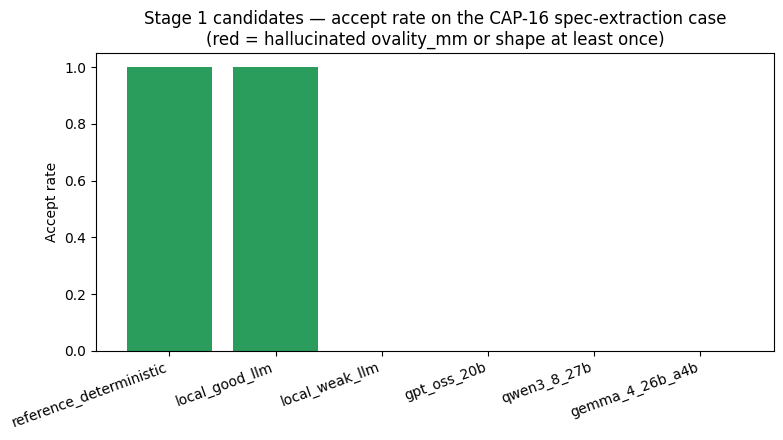

In [10]:
import matplotlib.pyplot as plt

plot_df = summary_df.copy()
# green >= 0.8 AND zero hallucinations, red if it EVER hallucinated (regardless of
# accept_rate -- a model that hallucinates even once on this one example is disqualifying,
# see Section 8), amber for partial credit with no hallucination.
def _bar_color(row):
    if row["hallucinated_ovality_or_shape"] > 0:
        return "#d64545"
    if (row["accept_rate"] or 0) >= 0.8:
        return "#2a9d5c"
    if (row["accept_rate"] or 0) > 0:
        return "#e0a63a"
    return "#d64545"

colors = [_bar_color(r) for _, r in plot_df.iterrows()]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(plot_df.index, plot_df["accept_rate"].fillna(0), color=colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accept rate")
ax.set_title("Stage 1 candidates — accept rate on the CAP-16 spec-extraction case\n(red = hallucinated ovality_mm or shape at least once)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("stage1_comparison.png", dpi=150)
plt.show()


## 7.5 Debug: inspect what a failing model actually produced

The summary table only shows the first failure reason as a one-liner. This
pulls the first failing trial per model (skips models with 0 trials or
where every trial passed) and prints the full raw output plus every reason
it was rejected.

In [11]:
for name, trials in all_trials.items():
    failing = [t for t in trials if t["verdict"] != "accept"]
    if not failing:
        continue
    worst = failing[0]
    print(f"===== {name} -- trial {worst['trial']} -- verdict: {worst['verdict']} =====")
    print("reasons:", worst["reasons"])
    print()
    if worst["raw_output"]:
        print(worst["raw_output"])
    else:
        print("(no output -- generation itself failed, see reasons above)")
    print()


===== local_weak_llm -- trial 0 -- verdict: reject =====
reasons: ['CRITICAL: hallucinated ovality_mm=0.5 (never stated in the email)', "CRITICAL: hallucinated shape='round' (never stated in the email)", 'did not flag the missing ovality tolerance in unresolved_questions (warning, not a reject)']

{"machine_id": "CAP-16", "part_family": "starwheel", "target_speed_cpm": 380, "container": {"description": "500 ml PET still water bottle", "body_diameter_mm": 64.0, "ovality_mm": 0.5, "height_mm": 210, "neck_finish": "PCO-1881", "closure": "28 mm plastic screw", "material": "PET", "filled_weight_g": 520, "shape": "round"}, "unresolved_questions": [], "feasibility_flags": []}

===== gpt_oss_20b -- trial 0 -- verdict: skipped =====
reasons: ['URLError: <urlopen error Tunnel connection failed: 403 Forbidden>']

(no output -- generation itself failed, see reasons above)

===== qwen3_8_27b -- trial 0 -- verdict: skipped =====
reasons: ['URLError: <urlopen error Tunnel connection failed: 403 Forbi

## 8. Reading these results

- `reference_deterministic` and `local_good_llm` should both hit **1.0**
  accept rate with **0** hallucinations -- two differently-worded but
  correct extractions, proving the harness judges *content*, not phrasing.
- `local_weak_llm` should hit **0.0** with `hallucinated_ovality_or_shape`
  showing **2** (not 0) -- it silently guesses both `ovality_mm` and
  `shape`, exactly the failure mode the source doc names. That is the
  harness working correctly, not a bug: **a Stage 1 candidate that
  hallucinates either field is disqualifying, full stop, regardless of how
  accurate the rest of its extraction is.** A model that gets
  `machine_id`, `target_speed_cpm`, and every dimension perfect but invents
  a plausible `ovality_mm` has produced a worse result than one that
  mis-spells the neck finish -- the former reaches a machined part
  unreviewed, the latter gets caught on the next read.
- `gpt_oss_20b`, `qwen3_8_27b`, and `gemma_4_26b_a4b` are the three real,
  currently-verified candidates from Section 2. In *this* sandbox run they
  show `skipped` (no network) -- open this notebook where OpenRouter is
  reachable, set `OPENROUTER_API_KEY` (Section 0), and re-run Section 6 for
  real numbers. Read `hallucinated_ovality_or_shape` first, before
  `accept_rate` -- a model with a merely-mediocre accept rate but zero
  hallucinations is a viable Stage 1 candidate to iterate the prompt on; a
  model with a great accept rate but any nonzero hallucination count is not,
  because that failure mode is exactly the one this stage exists to prevent.
- `unresolved_gap_not_flagged` is reported separately and does **not** by
  itself reject a result (see Section 5's design-decision note) -- treat a
  nonzero count here as "needs a tighter prompt", not "candidate is unsafe".

One worked email is not a benchmark. Extend Section 6 to loop over a batch
of real past customer requests -- including ones with different gaps
(missing neck finish, missing speed, ambiguous units) -- and compare
accept rate and hallucination rate across the whole batch before picking a
model for production.

## 9. Running this for real, and what it costs

1. Get an OpenRouter API key at openrouter.ai and fund the account (even a
   $0 balance triggers HTTP 402 on paid models, per OpenRouter's docs).
   ```bash
   export OPENROUTER_API_KEY=sk-or-...
   ```
2. Re-run Section 6. These are all cheap, mid-size models -- 5 trials per
   candidate on this one short prompt (~350 input + ~200 output tokens
   each) costs a small fraction of a cent for `gpt_oss_20b` and
   `gemma_4_26b_a4b`, and still well under a cent for `qwen3_8_27b`. A
   free variant (`openai/gpt-oss-20b:free`) also exists if you want to test
   `gpt_oss_20b` at zero cost first.
3. To go beyond one example: collect a batch of real (anonymized) past
   customer emails with known-correct extractions, loop Section 6 over all
   of them per model, and aggregate `accept_rate` and, especially,
   `hallucinated_ovality_or_shape` across the batch -- that aggregate,
   not this single worked example, is what should decide which model
   serves Stage 1 in production.
4. If a candidate's accept rate is good but not great, try constrained
   decoding / JSON-schema-mode (OpenRouter's `response_format` /
   provider-native structured outputs) before switching models -- the
   source doc notes constrained decoding helps far more here than a bigger
   model does.

## References

- gpt-oss-20b — model id and pricing: https://openrouter.ai/openai/gpt-oss-20b
- gpt-oss-20b free variant: https://openrouter.ai/openai/gpt-oss-20b:free
- Qwen3.8 27B — model id and pricing: https://openrouter.ai/qwen/qwen3.8-27b
- Gemma 4 26B A4B — model id and pricing: https://openrouter.ai/google/gemma-4-26b-a4b-it
- Gemma 4 31B (dense alternative considered) — model id and pricing: https://openrouter.ai/google/gemma-4-31b-it
- OpenRouter public models API (cross-check source): https://openrouter.ai/api/v1/models